# Fig. 4 C-G: song structure under heliox

* **C, D** zebra finch: heliox effect on intro and non-intro syllable duration and ISI
  (`feature ~ condition x intro + (1 | bird)`).
* **E, F** starling: heliox effect on syllable duration and ISI early, mid and late in the bout
  (`feature ~ condition x position + (1 | bird)`).
* **G** zebra finch: motifs per song (`motifs ~ condition + (1 | bird)`).

All effects are Regular Air minus Heliox, so negative values mean an increase under heliox.
Error bars are 95% confidence intervals (1.96 SE). Panels 4A and 4B are drawings and are not made here.

Input: `song_structure_data.pkl`, written by Cell SS1 of `data_figs`.

In [1]:
# Cell 1: settings, data
import os
import pickle
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy.stats import norm
from statsmodels.tools.sm_exceptions import ConvergenceWarning

# Paths relative to the repository, so a fresh clone runs without edits (from the repo folder or
# from notebooks/). To use other copies, e.g. on the cluster: export HELIOX_DATA_DIR=/path/to/data/derived
REPO = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
DATA_DIR = os.environ.get('HELIOX_DATA_DIR', os.path.join(REPO, 'data'))
FIG_DIR = os.environ.get('HELIOX_FIG_DIR', os.path.join(REPO, 'figures'))
DATA_PATH = os.path.join(DATA_DIR, 'song_structure_data.pkl')
os.makedirs(FIG_DIR, exist_ok=True)

# Effects are fitted in seconds. 's' plots them as fitted; 'ms' multiplies by 1000.
TIME_UNIT = 's'
SCALE = {'s': 1.0, 'ms': 1000.0}[TIME_UNIT]

plt.rcParams.update({'font.size': 15, 'axes.titlesize': 19, 'axes.labelsize': 17, 'xtick.labelsize': 16,
                     'ytick.labelsize': 15, 'legend.fontsize': 14, 'axes.spines.top': False,
                     'axes.spines.right': False, 'savefig.dpi': 300, 'savefig.bbox': 'tight'})
ORANGES = {2: ['#E67E22', '#C0392B'], 3: ['#E67E22', '#D35400', '#C0392B']}

with open(DATA_PATH, 'rb') as f:
    data = pickle.load(f)
print(f"zebra finch: {len(data['zf_syllables'])} syllables, {len(data['zf_songs'])} songs; "
      f"starling: {len(data['starling_syllables'])} syllables; made {data['meta']['created']}")


def stars(p):
    return '****' if p < 1e-4 else '***' if p < 1e-3 else '**' if p < 1e-2 else '*' if p < 0.05 else 'ns'


def contrast(result, weights):
    """A weighted sum of fixed effects with its Wald test. This is how the effect within one group
    (e.g. intro notes, or the late window) is read off a model with an interaction."""
    names = list(result.fe_params.index)
    missing = set(weights) - set(names)
    if missing:
        raise KeyError(f'{sorted(missing)} not among the model terms {names}')
    L = np.array([weights.get(n, 0.0) for n in names])
    cov = result.cov_params().loc[names, names].to_numpy()
    beta = float(L @ result.fe_params.to_numpy())
    se = float(np.sqrt(L @ cov @ L))
    return dict(beta=beta, se=se, z=beta / se, p=2 * norm.sf(abs(beta / se)), lo=beta - 1.96 * se, hi=beta + 1.96 * se)


def fit(formula, df, groups):
    """REML fit with statsmodels' defaults, as in the original analysis."""
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', ConvergenceWarning)   # 'MLE on the boundary' notes; checked below
        result = smf.mixedlm(formula, df, groups=df[groups]).fit()
    if not result.converged:
        print(f'[CHECK] {formula}: did not converge')
    return result


def draw_effects(ax, labels, effects, colors):
    """Points with 95% CI, and stars just past the end of each CI, on the side away from zero."""
    x = np.arange(len(labels))
    for xi, e, c in zip(x, effects, colors):
        ax.vlines(xi, e['lo'] * SCALE, e['hi'] * SCALE, color='black', lw=2.6, zorder=2)
        ax.scatter(xi, e['beta'] * SCALE, s=170, color=c, zorder=3, edgecolor='none')
        up = e['beta'] >= 0
        ax.annotate(stars(e['p']), xy=(xi, (e['hi'] if up else e['lo']) * SCALE), xytext=(0, 4 if up else -4),
                    textcoords='offset points', ha='center', va='bottom' if up else 'top', fontsize=19)
    ax.axhline(0, ls='--', lw=1.7, color='0.55', zorder=1)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=19)
    ax.set_xlim(-0.5, len(labels) - 0.5)
    ax.tick_params(axis='x', length=0)
    for side in ('left', 'bottom'):
        ax.spines[side].set_linewidth(1.7)
        ax.spines[side].set_color('0.45')


def bracket(ax, x1, x2, y, text, h, down=False):
    """A significance bracket from x1 to x2 at height y (pointing down when below the data)."""
    s = -1 if down else 1
    ax.plot([x1, x1, x2, x2], [y, y + s * h, y + s * h, y], lw=2.2, color='k', clip_on=False)
    ax.text((x1 + x2) / 2, y + s * 1.3 * h, text, ha='center', va='top' if down else 'bottom',
            fontsize=21, fontweight='bold')


def direction_labels(ax):
    """'Increased in Regular Air' above zero and 'Increased in Heliox' below, left of the y axis."""
    for y, text in [(1.0, 'Increased\nin Regular Air'), (0.0, 'Increased\nin Heliox')]:
        ax.text(-0.42, y, text, transform=ax.transAxes, ha='center', va='center', fontsize=15)

zebra finch: 63728 syllables, 2027 songs; starling: 95063 syllables; made 2026-10-11T12:19:24


In [2]:
# Cell 2: zebra finch models (Fig. 4 C, D, G)
zf = data['zf_syllables'].copy()
zf['heliox'] = zf['condition'] == 'heliox'
zf_fits = {feature: fit(f'{feature} ~ heliox * intro', zf.dropna(subset=[feature]), 'bird')
           for feature in ['duration', 'isi']}

# The model gives heliox - regular air; the paper reports regular air - heliox, hence the -1 weights.
HELIOX, INTERACTION = 'heliox[T.True]', 'heliox[T.True]:intro[T.True]'
zf_effects = {}
for feature, res in zf_fits.items():
    zf_effects[feature] = {
        'Intro': contrast(res, {HELIOX: -1, INTERACTION: -1}),
        'Non-intro': contrast(res, {HELIOX: -1}),
        'difference': contrast(res, {INTERACTION: -1}),       # does the effect differ between them?
    }

songs = data['zf_songs'].copy()
songs['heliox'] = songs['condition'] == 'heliox'
motif_fit = fit('motifs ~ heliox', songs, 'bird')
motif_effect = contrast(motif_fit, {HELIOX: -1})

table = pd.DataFrame([dict(feature=f, group=g, **e) for f, d in zf_effects.items() for g, e in d.items()]
                     + [dict(feature='motifs per song', group='all', **motif_effect)])
print('Regular air - heliox (s, or motifs per song):')
print(table.round(5).to_string(index=False))

Regular air - heliox (s, or motifs per song):
        feature      group     beta      se        z       p       lo       hi
       duration      Intro -0.00210 0.00100 -2.09309 0.03634 -0.00406 -0.00013
       duration  Non-intro  0.00020 0.00040  0.48938 0.62457 -0.00059  0.00098
       duration difference -0.00229 0.00107 -2.13622 0.03266 -0.00439 -0.00019
            isi      Intro  0.01197 0.00228  5.25178 0.00000  0.00750  0.01643
            isi  Non-intro -0.00059 0.00087 -0.68697 0.49210 -0.00229  0.00110
            isi difference  0.01256 0.00243  5.17864 0.00000  0.00781  0.01731
motifs per song        all  1.81708 0.15135 12.00546 0.00000  1.52043  2.11373


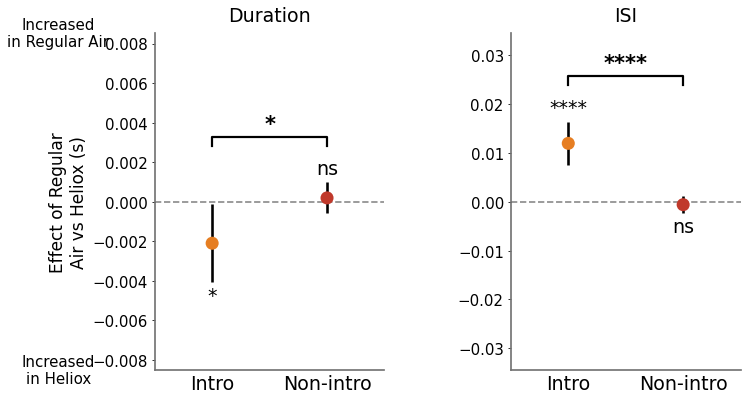

In [3]:
# Cell 3: Fig. 4 C-D, zebra finch duration and ISI, intro vs non-intro
fig, axes = plt.subplots(1, 2, figsize=(10.5, 6.2), gridspec_kw=dict(wspace=0.55))
for ax, (feature, title) in zip(axes, [('duration', 'Duration'), ('isi', 'ISI')]):
    eff = zf_effects[feature]
    draw_effects(ax, ['Intro', 'Non-intro'], [eff['Intro'], eff['Non-intro']], ORANGES[2])
    top = max(0, eff['Intro']['hi'], eff['Non-intro']['hi']) * SCALE
    span = max(abs(eff['Intro']['lo']), abs(eff['Intro']['hi']), abs(eff['Non-intro']['hi']), abs(eff['Non-intro']['lo'])) * SCALE
    bracket(ax, 0, 1, top + 0.45 * span, stars(eff['difference']['p']), 0.12 * span)
    ax.set_ylim(-2.1 * span, 2.1 * span)                 # zero in the middle, room for the bracket
    ax.set_title(title, pad=12)
axes[0].set_ylabel(f'Effect of Regular\nAir vs Heliox ({TIME_UNIT})')
direction_labels(axes[0])
fig.savefig(os.path.join(FIG_DIR, 'fig4CD_zebra_finch_intro.png'))
fig.savefig(os.path.join(FIG_DIR, 'fig4CD_zebra_finch_intro.pdf'))
plt.show()

early    10747
mid       9251
late     10753

duration, regular air - heliox (s):
                  beta       se        z        p
Early          0.07380  0.00899  8.21262  0.00000
Mid            0.03223  0.00976  3.30269  0.00096
Late           0.08039  0.00898  8.95046  0.00000
(Early, Mid)  -0.04157  0.01285 -3.23558  0.00121
(Early, Late)  0.00659  0.01225  0.53812  0.59049
(Mid, Late)    0.04816  0.01284  3.74984  0.00018

isi, regular air - heliox (s):
                  beta       se         z        p
Early         -0.13337  0.01469  -9.07996  0.00000
Mid           -0.11237  0.01359  -8.27138  0.00000
Late          -0.12881  0.01252 -10.28838  0.00000
(Early, Mid)   0.02100  0.01943   1.08123  0.27959
(Early, Late)  0.00456  0.01868   0.24425  0.80704
(Mid, Late)   -0.01644  0.01779  -0.92424  0.35536


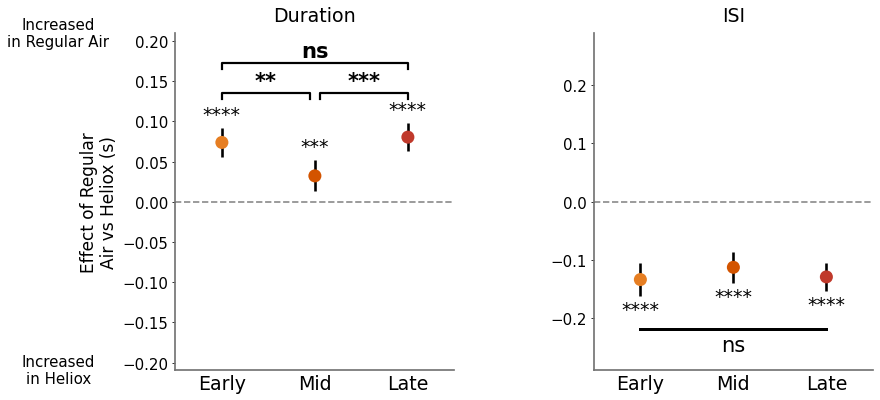

In [4]:
# Cell 4: starling models and Fig. 4 E-F, duration and ISI early, mid and late in the bout
# Windows of normalized position in the bout (0 = first syllable, 1 = last): first 10%, central 10%,
# last 10%. Syllables in between are not used.
st = data['starling_syllables'].copy()
r = st['position_norm']
st['window'] = np.select([r <= 0.10, (r > 0.45) & (r <= 0.55), r >= 0.90], ['early', 'mid', 'late'], default='')
st = st[st['window'] != ''].copy()
st['window'] = pd.Categorical(st['window'], ['early', 'mid', 'late'], ordered=True)   # early is the reference
st['condition'] = st['condition'].astype('category')                                  # heliox is the reference
print(st['window'].value_counts().reindex(['early', 'mid', 'late']).to_string())

# condition[T.regair] is already regular air - heliox, so the weights here are +1.
COND, MID, LATE = 'condition[T.regair]', 'condition[T.regair]:window[T.mid]', 'condition[T.regair]:window[T.late]'
st_fits, st_effects = {}, {}
for feature in ['duration', 'isi']:
    res = fit(f'{feature} ~ condition * window', st.dropna(subset=[feature]), 'bird')
    st_fits[feature] = res
    st_effects[feature] = {
        'Early': contrast(res, {COND: 1}), 'Mid': contrast(res, {COND: 1, MID: 1}),
        'Late': contrast(res, {COND: 1, LATE: 1}),
        # does the effect differ between two windows? (the condition x window interactions)
        ('Early', 'Mid'): contrast(res, {MID: 1}), ('Early', 'Late'): contrast(res, {LATE: 1}),
        ('Mid', 'Late'): contrast(res, {LATE: 1, MID: -1})}
    print(f'\n{feature}, regular air - heliox (s):')
    print(pd.DataFrame(st_effects[feature]).T[['beta', 'se', 'z', 'p']].round(5).to_string())

WINDOWS = ['Early', 'Mid', 'Late']
fig, axes = plt.subplots(1, 2, figsize=(12.5, 6.2), gridspec_kw=dict(wspace=0.5))
for ax, (feature, title) in zip(axes, [('duration', 'Duration'), ('isi', 'ISI')]):
    eff = st_effects[feature]
    draw_effects(ax, WINDOWS, [eff[w] for w in WINDOWS], ORANGES[3])
    span = max(max(abs(eff[w]['lo']), abs(eff[w]['hi'])) for w in WINDOWS) * SCALE
    sign = 1 if np.mean([eff[w]['beta'] for w in WINDOWS]) >= 0 else -1    # brackets go on the data's side
    edge = max(abs(eff[w]['hi' if sign > 0 else 'lo']) for w in WINDOWS) * SCALE
    pairs = [('Early', 'Mid'), ('Mid', 'Late'), ('Early', 'Late')]
    if all(eff[pair]['p'] >= 0.05 for pair in pairs):
        # no window differs from another: one line over all three, as in the paper
        y = sign * (edge + 0.35 * span)
        ax.plot([0, 2], [y, y], lw=3, color='k')
        ax.text(1, y + sign * 0.06 * span, 'ns', ha='center', va='bottom' if sign > 0 else 'top', fontsize=21)
        reach = edge + 0.65 * span
    else:
        # neighbouring windows on the first level, early vs late on the second
        for level, (a, b) in zip([0, 0, 1], pairs):
            inset = 0.05 if level == 0 else 0.0               # keeps the two first-level brackets apart
            y = sign * (edge + (0.3 + 0.38 * level) * span)
            bracket(ax, WINDOWS.index(a) + (inset if a == 'Mid' else 0), WINDOWS.index(b) - (inset if b == 'Mid' else 0),
                    y, stars(eff[(a, b)]['p']), 0.08 * span, down=sign < 0)
        reach = edge + 0.98 * span
    ax.set_ylim(-1.08 * reach, 1.08 * reach)               # zero in the middle
    ax.set_title(title, pad=12)
axes[0].set_ylabel(f'Effect of Regular\nAir vs Heliox ({TIME_UNIT})')
direction_labels(axes[0])
fig.savefig(os.path.join(FIG_DIR, 'fig4EF_starling_position.png'))
fig.savefig(os.path.join(FIG_DIR, 'fig4EF_starling_position.pdf'))
plt.show()

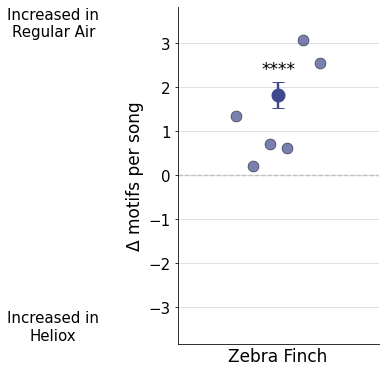

regular air - heliox, mean motifs per song by bird:
bird
z_p7y2_23      1.340
z_r11g11_24    0.218
z_y11c13_24    0.721
z_c8c19_24     0.612
z_g14g16_24    3.060
z_p4g13_23     2.541


In [5]:
# Cell 5: Fig. 4 G, motifs per song in zebra finches
# Small points: each bird's mean motifs per song in regular air minus in heliox.
# Large point: the model estimate with its 95% CI.
BIRD_ORDER = ['z_p7y2_23', 'z_r11g11_24', 'z_y11c13_24', 'z_c8c19_24', 'z_g14g16_24', 'z_p4g13_23']   # left to right, as in V130
per_bird = songs.pivot_table(index='bird', columns='condition', values='motifs', aggfunc='mean')
per_bird = (per_bird['regair'] - per_bird['heliox']).reindex([b for b in BIRD_ORDER if b in per_bird.index]
                                                          + sorted(set(per_bird.index) - set(BIRD_ORDER)))
color = '#40498E'
fig, ax = plt.subplots(figsize=(3.6, 6.2))
ax.axhline(0, color='k', ls='--', lw=1.2, alpha=0.6, zorder=1)
ax.scatter(np.linspace(-0.05, 0.05, len(per_bird)), per_bird.to_numpy(), s=120, color=color,
           edgecolor='black', alpha=0.7, lw=0.6, zorder=3)
e = motif_effect
ax.errorbar(0, e['beta'], yerr=[[e['beta'] - e['lo']], [e['hi'] - e['beta']]], fmt='o', color=color,
            capsize=6, lw=2.4, markersize=13, zorder=4)
ax.annotate(stars(e['p']), xy=(0, e['hi']), xytext=(0, 4), textcoords='offset points', ha='center',
            va='bottom', fontsize=17)
reach = 1.25 * max(abs(per_bird).max(), abs(e['hi']), abs(e['lo']))
ax.set_ylim(-reach, reach)
ax.yaxis.grid(True, color='0.85', lw=0.8)
ax.set_xlim(-0.12, 0.12)
ax.set_xticks([])
ax.set_xlabel('Zebra Finch')
ax.set_ylabel('Δ motifs per song')
for y, text in [(0.95, 'Increased in\nRegular Air'), (0.05, 'Increased in\nHeliox')]:
    ax.text(-0.62, y, text, transform=ax.transAxes, ha='center', va='center', fontsize=15)
fig.savefig(os.path.join(FIG_DIR, 'fig4G_zebra_finch_motifs.png'))
fig.savefig(os.path.join(FIG_DIR, 'fig4G_zebra_finch_motifs.pdf'))
plt.show()
print('regular air - heliox, mean motifs per song by bird:')
print(per_bird.round(3).to_string())